# FraudLens | Fraud Risk & Review Prioritisation
**Risk analytics portfolio project · Python · Business decision support**

> **Business question:** If a fraud team can review only a small share of transactions, can a statistical model identify more labelled fraud cases than a simple amount-based rule at the same review capacity?

This project follows a decision-first analytics workflow: define the decision, understand the data, quantify risk patterns, compare approaches fairly, and translate results into an operational recommendation.

**What this analysis can and cannot establish**
- The target `Class` indicates transactions labelled as fraud in this dataset.
- `V1`–`V28` are anonymised input features; their individual meanings are not available here.
- `Amount` is analysed in the dataset's original units; no currency is assumed.
- The model comparison is a portfolio experiment, not evidence of production readiness.

## 1. Set up the analysis

Keep the source file `transactions.csv` in the same folder as this notebook. The code below checks the expected columns and makes the main choices explicit.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
)

DATA_PATH = Path("transactions.csv")
TARGET = "Class"
RANDOM_STATE = 42
REVIEW_CAPACITY = 0.02  # operational comparison: highest-scoring 2% of test transactions

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find transactions.csv. Put the dataset next to this notebook "
        "or update DATA_PATH to the file location."
    )

df = pd.read_csv(DATA_PATH)

required_columns = {"Time", "Amount", TARGET}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if not set(df[TARGET].dropna().unique()).issubset({0, 1}):
    raise ValueError("Class must contain only 0 (non-fraud) and 1 (fraud).")

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Missing cells: {df.isna().sum().sum():,}")
print(f"Duplicate rows (beyond first copy): {df.duplicated().sum():,}")
df.head()

Rows: 284,807 | Columns: 31
Missing cells: 0
Duplicate rows (beyond first copy): 1,081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Establish the baseline: how rare is labelled fraud?

Accuracy is misleading for highly imbalanced data: a system that labels every transaction as non-fraud would be correct almost all the time. Start with the fraud count and prevalence instead.

,Measure,Value
0,Total transactions,"284,807"
1,Labelled fraud cases,492
2,Non-fraud cases,"284,315"
3,Fraud prevalence,0.173%


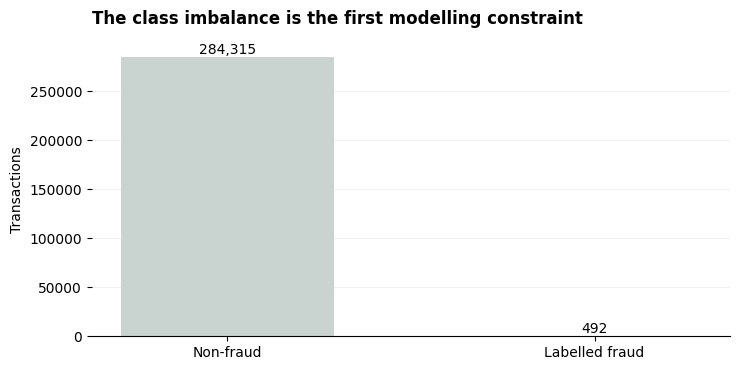

In [2]:
class_counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
fraud_count = int(class_counts.loc[1])
non_fraud_count = int(class_counts.loc[0])
fraud_rate = fraud_count / len(df)

summary = pd.DataFrame({
    "Measure": ["Total transactions", "Labelled fraud cases", "Non-fraud cases", "Fraud prevalence"],
    "Value": [f"{len(df):,}", f"{fraud_count:,}", f"{non_fraud_count:,}", f"{fraud_rate:.3%}"]
})
display(summary)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(["Non-fraud", "Labelled fraud"], [non_fraud_count, fraud_count],
              color=["#C9D4D0", "#D87862"], width=0.58)
ax.set_title("The class imbalance is the first modelling constraint", loc="left", weight="bold", pad=14)
ax.set_ylabel("Transactions")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
for bar, val in zip(bars, [non_fraud_count, fraud_count]):
    ax.text(bar.get_x() + bar.get_width()/2, val, f"{val:,}", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()

**How to read this:** fraud is a rare event in the dataset. That is why the project evaluates precision, recall, and precision–recall performance rather than relying on accuracy alone.

## 3. Check data quality before interpreting patterns

Duplicate records may be legitimate repeated observations or data artefacts. We quantify them, but do **not** automatically remove them: removing rows without understanding their origin could alter the population being analysed.

In [3]:
quality = pd.DataFrame({
    "Check": ["Rows", "Columns", "Missing cells", "Exact duplicate rows beyond first copy",
              "Rows that belong to a duplicate group", "Negative transaction amounts"],
    "Result": [
        f"{len(df):,}", f"{df.shape[1]:,}", f"{df.isna().sum().sum():,}",
        f"{df.duplicated().sum():,}", f"{df.duplicated(keep=False).sum():,}",
        f"{(df['Amount'] < 0).sum():,}"
    ]
})
display(quality)

# Confirm whether exact duplicate feature rows disagree on the target label.
feature_cols = [c for c in df.columns if c != TARGET]
label_conflicts = (
    df.groupby(feature_cols, dropna=False)[TARGET].nunique().gt(1).sum()
)
print(f"Exact feature combinations associated with conflicting Class labels: {label_conflicts:,}")

,Check,Result
0,Rows,"284,807"
1,Columns,31
2,Missing cells,0
3,Exact duplicate rows beyond first copy,"1,081"
4,Rows that belong to a duplicate group,"1,854"
5,Negative transaction amounts,0


Exact feature combinations associated with conflicting Class labels: 0


**Interpretation rule:** this notebook retains the provided rows for the primary analysis. Duplicate sensitivity should be revisited with dataset documentation or domain context; this check alone cannot determine whether duplicates are erroneous.

## 4. Identify where labelled fraud is concentrated

Amount segments can answer two different questions:
1. **Fraud rate within a segment:** how risky is a transaction in that band?
2. **Share of all fraud cases:** how much of the observed fraud population comes from that band?

These are not interchangeable. A small, high-risk segment may contain few cases, while a large segment with a lower rate may account for more cases.

In [4]:
amount_bins = [-0.001, 25, 100, 250, 500, np.inf]
amount_labels = ["0–25", "25–100", "100–250", "250–500", "500+"]

amount_analysis = df.copy()
amount_analysis["Amount band"] = pd.cut(
    amount_analysis["Amount"], bins=amount_bins, labels=amount_labels, right=False
)

amount_summary = (
    amount_analysis.groupby("Amount band", observed=False)
    .agg(
        Transactions=(TARGET, "size"),
        Fraud_cases=(TARGET, "sum"),
        Fraud_rate=(TARGET, "mean"),
        Total_amount=("Amount", "sum")
    )
    .reindex(amount_labels)
)
amount_summary["Share_of_fraud_cases"] = amount_summary["Fraud_cases"] / fraud_count
display(
    amount_summary.assign(
        Fraud_rate_pct=(amount_summary["Fraud_rate"] * 100).round(3),
        Share_of_fraud_pct=(amount_summary["Share_of_fraud_cases"] * 100).round(1)
    )[["Transactions", "Fraud_cases", "Fraud_rate_pct", "Share_of_fraud_pct"]]
)

,Transactions,Fraud_cases,Fraud_rate_pct,Share_of_fraud_pct
Amount band,,,,
0–25,148966,275,0.185,55.9
25–100,78456,87,0.111,17.7
100–250,34482,56,0.162,11.4
250–500,13411,39,0.291,7.9
500+,9492,35,0.369,7.1


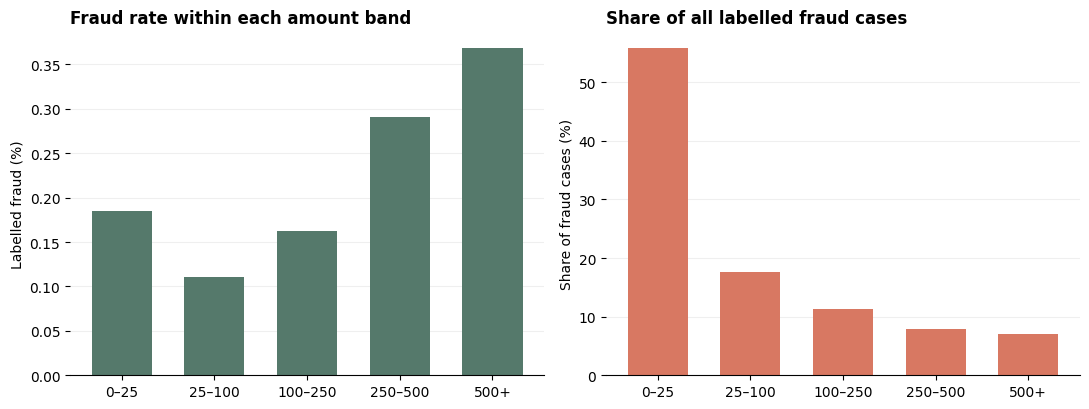

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(amount_labels))
axes[0].bar(x, amount_summary["Fraud_rate"] * 100, color="#55796B", width=0.65)
axes[0].set_title("Fraud rate within each amount band", loc="left", weight="bold")
axes[0].set_ylabel("Labelled fraud (%)")
axes[0].set_xticks(x, amount_labels)
axes[1].bar(x, amount_summary["Share_of_fraud_cases"] * 100, color="#D87862", width=0.65)
axes[1].set_title("Share of all labelled fraud cases", loc="left", weight="bold")
axes[1].set_ylabel("Share of fraud cases (%)")
axes[1].set_xticks(x, amount_labels)
for ax in axes:
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Business takeaway:** use the table and both charts together. Do not label a band “the riskiest” solely because it contains the most fraud cases; compare its within-band rate as well. Amount alone is only a simple prioritisation signal, not proof of fraud.

## 5. Define a fair model evaluation

We split the data into training, validation, and test sets. The training set fits the model; the validation set chooses a decision threshold; the test set is held back for the final comparison.

A logistic regression model is used as a clear baseline. Features are standardised, and class weights help the model account for the rare positive class. We exclude `Class` from predictors.

In [6]:
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# 60% training, 20% validation, 20% final test; stratification preserves class proportions.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Split sizes")
for name, X_part, y_part in [
    ("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)
]:
    print(f"{name:10s}: {len(X_part):>7,} rows | fraud: {int(y_part.sum()):>3,} ({y_part.mean():.3%})")

model = Pipeline(steps=[
    ("scale", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE
    ))
])
model.fit(X_train, y_train)

validation_scores = model.predict_proba(X_val)[:, 1]
test_scores = model.predict_proba(X_test)[:, 1]

Split sizes
Train     : 170,884 rows | fraud: 295 (0.173%)
Validation:  56,961 rows | fraud:  98 (0.172%)
Test      :  56,962 rows | fraud:  99 (0.174%)


## 6. Choose the review threshold using validation data only

A fixed probability threshold such as 0.50 is not automatically the right business choice. Here, we choose the threshold that flags approximately the top 2% of validation transactions. We then apply that threshold once to the held-out test set.

The 2% capacity is an illustrative planning assumption, not a universal operational target.

In [7]:
validation_threshold = np.quantile(validation_scores, 1 - REVIEW_CAPACITY)
val_pred = (validation_scores >= validation_threshold).astype(int)

print(f"Illustrative review capacity: {REVIEW_CAPACITY:.1%}")
print(f"Threshold selected on validation data: {validation_threshold:.4f}")
print(f"Validation alert share: {val_pred.mean():.2%}")
print(f"Validation recall at this threshold: {recall_score(y_val, val_pred):.2%}")

Illustrative review capacity: 2.0%
Threshold selected on validation data: 0.5397
Validation alert share: 2.00%
Validation recall at this threshold: 86.73%


## 7. Evaluate once on the held-out test set

Precision answers “of the transactions flagged, how many were labelled fraud?” Recall answers “of all labelled fraud cases, how many did we flag?” Both are needed to understand the operational trade-off.

In [8]:
test_pred = (test_scores >= validation_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()

test_metrics = {
    "Test transactions": len(y_test),
    "Labelled fraud cases": int(y_test.sum()),
    "Alerts raised": int(test_pred.sum()),
    "True positives (fraud detected)": int(tp),
    "False positives (non-fraud flagged)": int(fp),
    "False negatives (fraud missed)": int(fn),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "Average precision": average_precision_score(y_test, test_scores)
}
display(pd.DataFrame({"Metric": list(test_metrics.keys()), "Result": [
    f"{v:,}" if isinstance(v, (int, np.integer)) else f"{v:.3%}" if k in ["Precision", "Recall", "Average precision"] else f"{v:.4f}"
    for k, v in test_metrics.items()
]}))

,Metric,Result
0,Test transactions,"56,962"
1,Labelled fraud cases,99
2,Alerts raised,"1,224"
3,True positives (fraud detected),90
4,False positives (non-fraud flagged),"1,134"
5,False negatives (fraud missed),9
6,Precision,7.353%
7,Recall,90.909%
8,ROC-AUC,0.9662
9,Average precision,75.753%


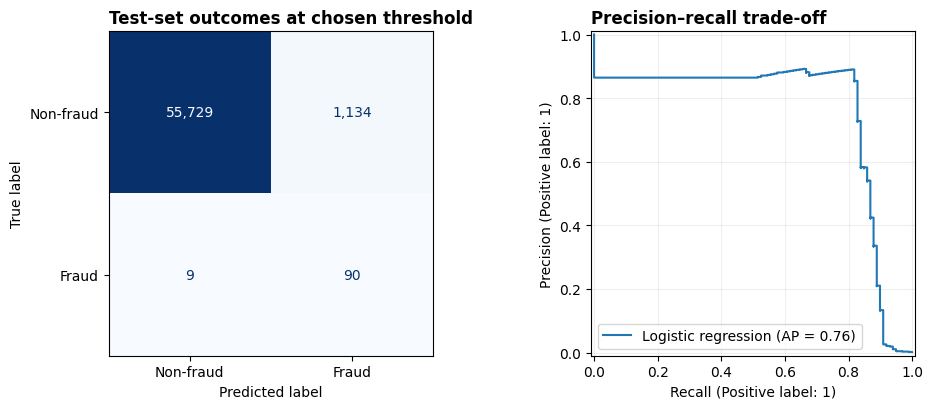

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=[0, 1], display_labels=["Non-fraud", "Fraud"],
    cmap="Blues", colorbar=False, ax=axes[0], values_format=","
)
axes[0].set_title("Test-set outcomes at chosen threshold", loc="left", weight="bold")
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[1], name="Logistic regression")
axes[1].set_title("Precision–recall trade-off", loc="left", weight="bold")
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretation guide**
- **True positives:** labelled fraud cases surfaced for review.
- **False positives:** legitimate transactions that would consume review capacity.
- **False negatives:** labelled fraud cases not surfaced at the selected threshold.
- **Precision–recall curve:** shows how detection and alert quality change as the threshold moves.

Because the feature names are anonymised, model coefficients cannot be translated into familiar transaction behaviours without additional documentation.

## 8. Does the model beat a simple rule at the same capacity?

We compare the model with a basic rule that prioritises the largest transaction amounts. Both methods flag the same number of test transactions, so the comparison focuses on how many labelled fraud cases each approach finds under an equal alert budget.

This is a baseline, not a recommendation to use transaction amount as the sole fraud signal.

In [10]:
n_test = len(y_test)
n_alerts = max(1, int(np.ceil(REVIEW_CAPACITY * n_test)))

# Top model scores and top amounts each receive the same number of review slots.
model_order = np.argsort(-test_scores)
amount_test = X_test["Amount"].to_numpy()
amount_order = np.argsort(-amount_test)

model_alert_mask = np.zeros(n_test, dtype=bool)
amount_alert_mask = np.zeros(n_test, dtype=bool)
model_alert_mask[model_order[:n_alerts]] = True
amount_alert_mask[amount_order[:n_alerts]] = True

y_test_array = y_test.to_numpy()
def evaluate_alert_mask(mask, labels):
    detected = int(labels[mask].sum())
    return {
        "Alerts": int(mask.sum()),
        "Fraud cases detected": detected,
        "Recall": detected / max(1, int(labels.sum())),
        "Precision": detected / max(1, int(mask.sum()))
    }

comparison = pd.DataFrame({
    "Logistic regression": evaluate_alert_mask(model_alert_mask, y_test_array),
    "Highest-amount rule": evaluate_alert_mask(amount_alert_mask, y_test_array)
}).T
display(comparison.style.format({
    "Alerts": "{:,.0f}", "Fraud cases detected": "{:,.0f}",
    "Recall": "{:.2%}", "Precision": "{:.2%}"
}))

,Alerts,Fraud cases detected,Recall,Precision
Logistic regression,"1,140",90,90.91%,7.89%
Highest-amount rule,"1,140",2,2.02%,0.18%


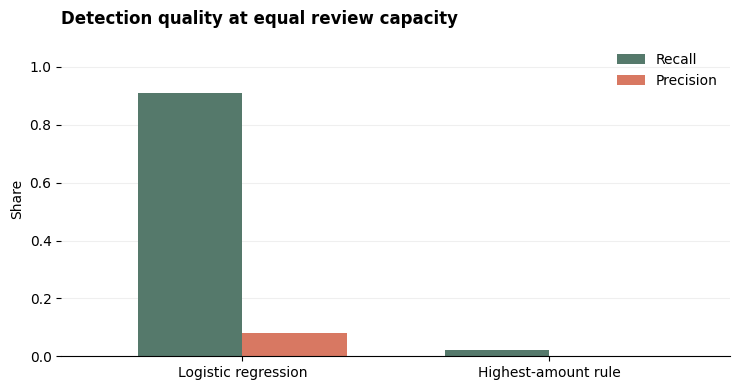

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
comparison[["Recall", "Precision"]].plot(kind="bar", ax=ax, color=["#55796B", "#D87862"], width=0.68)
ax.set_title("Detection quality at equal review capacity", loc="left", weight="bold", pad=12)
ax.set_ylabel("Share")
ax.set_ylim(0, max(0.1, comparison[["Recall", "Precision"]].to_numpy().max() * 1.2))
ax.set_xticklabels(comparison.index, rotation=0)
ax.legend(["Recall", "Precision"], frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 9. Executive conclusion

The following cells generate a concise, data-backed summary from the actual test results. Read it alongside the charts before deciding what recommendation is justified.

In [12]:
model_recall = comparison.loc["Logistic regression", "Recall"]
rule_recall = comparison.loc["Highest-amount rule", "Recall"]
model_precision = comparison.loc["Logistic regression", "Precision"]
rule_precision = comparison.loc["Highest-amount rule", "Precision"]
extra_detected = int(
    comparison.loc["Logistic regression", "Fraud cases detected"]
    - comparison.loc["Highest-amount rule", "Fraud cases detected"]
)
fraud_band = amount_summary["Fraud_rate"].idxmax()
case_band = amount_summary["Fraud_cases"].idxmax()

print("EXECUTIVE SUMMARY")
print("-" * 60)
print(f"Dataset contains {len(df):,} transactions and {fraud_count:,} labelled fraud cases ({fraud_rate:.3%}).")
print(f"Highest observed within-band fraud rate: {fraud_band}.")
print(f"Largest number of labelled fraud cases by amount band: {case_band}.")
print(f"At the same review capacity ({n_alerts:,} test alerts):")
print(f"  • Logistic regression detected {int(comparison.loc['Logistic regression', 'Fraud cases detected'])} fraud cases "
      f"(recall {model_recall:.2%}, precision {model_precision:.2%}).")
print(f"  • Highest-amount rule detected {int(comparison.loc['Highest-amount rule', 'Fraud cases detected'])} fraud cases "
      f"(recall {rule_recall:.2%}, precision {rule_precision:.2%}).")
print(f"  • Difference in fraud cases detected by the model versus the rule: {extra_detected:+d}.")

EXECUTIVE SUMMARY
------------------------------------------------------------
Dataset contains 284,807 transactions and 492 labelled fraud cases (0.173%).
Highest observed within-band fraud rate: 500+.
Largest number of labelled fraud cases by amount band: 0–25.
At the same review capacity (1,140 test alerts):
  • Logistic regression detected 90 fraud cases (recall 90.91%, precision 7.89%).
  • Highest-amount rule detected 2 fraud cases (recall 2.02%, precision 0.18%).
  • Difference in fraud cases detected by the model versus the rule: +88.


### Recommended next steps

1. **Use the equal-capacity comparison to guide the recommendation.** If the model surfaces more labelled fraud cases, propose a controlled pilot; if not, investigate why before recommending it.
2. **Validate with time-based testing.** This random split measures performance on held-out rows, not on future periods. A chronological evaluation is needed before real deployment.
3. **Add interpretable operational signals.** The `V1`–`V28` fields are anonymised, so collaborate with a data owner to map them to usable business definitions where possible.
4. **Review false positives with domain experts.** High alert volume can increase customer friction and investigation cost.
5. **Monitor performance over time.** Fraud patterns, prevalence, and data quality can change.

### Limitations
- The dataset is highly imbalanced and contains anonymised features.
- The amount-based baseline is intentionally simple.
- A 2% alert budget is illustrative; actual review capacity and the cost of missed fraud should determine the operating point.
- Results are offline estimates, not a guarantee of future performance or financial savings.
- The transaction amount is not assumed to be a specific currency, and flagged transaction value is not the same as confirmed fraud loss.

---
**Portfolio note:** This project demonstrates a complete analytical decision loop—data quality, risk segmentation, interpretable baseline modelling, capacity-aware evaluation, benchmark comparison, and an evidence-based recommendation. Keep the code cells visible and rerun the notebook from top to bottom before publishing.